# 모듈 2 · NLP 미니프로젝트 — BERT 기반 한국어 의미 검색 시스템 개발 및 성능 비교

**기간:** 2일·총 16교시 · **체크포인트:** Day 1 `CP-01~06`, Day 2 `CP-07~10`  
**검색 모델:** TF-IDF · `klue/bert-base` · 한국어 Sentence-BERT  
**최종 결과물:** `search_docs()` + 검색 성능 보고서 + 기술적 의사결정 기록(ADR)

> 이 프로젝트는 GPT로 답변을 생성하거나 BERT를 재학습하는 프로젝트가 아닙니다. **문서의 표현 → 유사도 계산 → Top-k 검색 → 정답 평가 → 오류 분석 → 최종 검색 방식 선정**을 직접 개발합니다.
>
> **학생용 안내:** `[학생 구현]` 셀의 `TODO`를 작성하고 `raise NotImplementedError(...)`를 지운 뒤 `[공통 검증]` 셀을 실행하세요. `[기록]`으로 표시된 Markdown 셀은 실제 결과를 보고 직접 작성합니다. `생각해 볼 질문`은 별도 제출이 아닙니다.


## 00. 환경 설치와 세션 초기화 복구

GPU 세션이 초기화되더라도 첫 코드 셀부터 다시 실행할 수 있도록 구성했습니다. 패키지·모델 가중치·데이터가 없는 경우 자동으로 준비하며, 이미 저장된 파일은 재사용합니다.


**환경 설치(공통).** 필요한 Python 패키지를 한 번에 점검하고 누락되거나 호환 범위를 벗어난 패키지만 설치합니다. GPU 이미지에 이미 설치된 CUDA용 PyTorch는 가능한 한 유지하며, 설치 후 CUDA 상태를 확인합니다.


In [2]:
# [공통] 00-1 — 필요한 패키지 자동 설치
import sys, subprocess, importlib.metadata as im
from importlib.util import find_spec

# Python 패키지가 GPU 세션 초기화로 사라진 경우에도 첫 셀부터 복구합니다.
# RunPod GPU 이미지의 PyTorch/CUDA 조합은 가능하면 변경하지 않습니다.
requirements = [
    ('torch', 'torch>=2.2', '2.2'),
    ('numpy', 'numpy>=1.24', '1.24'),
    ('pandas', 'pandas>=2.0', '2.0'),
    ('matplotlib', 'matplotlib>=3.7', '3.7'),
    ('sklearn', 'scikit-learn>=1.3', '1.3'),
    ('transformers', 'transformers>=4.46,<5', '4.46'),
    ('datasets', 'datasets>=3.0,<5', '3.0'),
    ('sentence_transformers', 'sentence-transformers>=3.0,<6', '3.0'),
    ('safetensors', 'safetensors>=0.4', '0.4'),
    ('hf_transfer', 'hf_transfer>=0.1.9', '0.1.9'),
    ('hf_xet', 'hf_xet>=0.1.0', '0.1.0')
]

# 설치 확인에는 표준 라이브러리만 사용합니다.
to_install = []
for module, spec, min_version in requirements:
    if find_spec(module) is None:
        to_install.append(spec)
    else:
        try:
            package = {'sklearn': 'scikit-learn', 'sentence_transformers': 'sentence-transformers'}.get(module, module)
            version = im.version(package)
            major_minor = tuple(int(x) for x in version.split('.')[:2])
            required = tuple(int(x) for x in min_version.split('.'))
            if major_minor < required or (module in ('transformers','datasets') and int(version.split('.')[0]) >= 5):
                to_install.append(spec)
        except (im.PackageNotFoundError, ValueError):
            to_install.append(spec)

if to_install:
    print('설치/갱신:', ', '.join(to_install))
    # subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *to_install])
    subprocess.check_call(["uv", "pip", "install", "--python", sys.executable, "-q", *to_install])
else:
    print('필수 패키지가 이미 준비되어 있습니다.')

# 이미 import한 구버전 라이브러리가 변경된 경우에는 커널 재시작 후 다시 실행하세요.
print('Python:', sys.version.split()[0])


설치/갱신: hf_transfer>=0.1.9
Python: 3.11.18


**작업 폴더와 장치 확인(공통).** `/workspace`가 있으면 프로젝트 파일을 그 아래에, 그 외 환경은 현재 작업 폴더 아래에 보관합니다. 모든 파일·폴더는 처음 실행할 때 자동으로 생성되며 추론 결과는 재실행 시 캐시를 재사용합니다.


In [3]:
# [공통] 00-2 — 프로젝트 경로·GPU·캐시 설정
import os, json, re, hashlib, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

# ROOT = (Path('/workspace') if Path('/workspace').is_dir() else Path.cwd()) / 'nlp_bert_mini'
ROOT = Path("..")
DATA_RAW = ROOT / 'data' / 'raw'
DATA_PROCESSED = ROOT / 'data' / 'processed'
WEIGHTS = ROOT / 'weights'
CACHE = ROOT / 'outputs' / 'cache'
TABLES = ROOT / 'outputs' / 'tables'
FIGURES = ROOT / 'outputs' / 'figures'
REPORTS = ROOT / 'outputs' / 'reports'
DOCS = ROOT / 'docs'
for folder in [DATA_RAW, DATA_PROCESSED, WEIGHTS, CACHE, TABLES, FIGURES, REPORTS, DOCS]:
    folder.mkdir(parents=True, exist_ok=True)

os.environ['HF_HOME'] = str(WEIGHTS / 'huggingface')
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('실습 루트:', ROOT)
print('PyTorch:', torch.__version__, '| Device:', DEVICE)
if DEVICE.type == 'cuda':
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('GPU가 없어 CPU로 실행합니다. BERT 임베딩 계산은 더 오래 걸릴 수 있습니다.')

# [공통] CP-08의 Sentence-BERT 가중치(pytorch_model.bin)는 PyTorch 버전이 낮으면 읽지 못할 수 있어 미리 확인합니다.
try:
    _torch_major_minor = tuple(int(x) for x in torch.__version__.split('+')[0].split('.')[:2])
except ValueError:
    _torch_major_minor = None
if _torch_major_minor is not None and _torch_major_minor < (2, 6):
    print('[주의] PyTorch가 2.6 미만입니다. Day 2의 CP-08에서 Sentence-BERT 로딩이 실패할 수 있으니 강사에게 알려 주세요.')


실습 루트: ..
PyTorch: 2.15.0+cu134 | Device: cuda
GPU: NVIDIA GeForce RTX 3060 Laptop GPU


### 세션 초기화 시 재실행 방법

1. GitHub에는 **작성한 Notebook과 최종 문서**를 저장하세요. 대용량 모델·원본 데이터는 업로드하지 않습니다.
2. 다음 날 Notebook을 내려받아 **00번 환경 셀부터 순서대로 실행**하면 폴더와 다운로드 데이터가 자동으로 준비됩니다.
3. `/workspace`가 영구 볼륨에 연결되어 있으면 캐시를 재사용합니다. 컨테이너가 삭제되는 환경에서는 다운로드와 임베딩 계산이 다시 진행될 수 있습니다.
4. CP-01~09는 Validation 질문만 사용합니다. **Test 질문의 정답은 CP-10에서 처음 열어 최종 평가**합니다.

**저장 위치:** `data/processed/` (문서·질문), `weights/` (모델 캐시), `outputs/cache/` (문서 벡터), `outputs/tables/` (성능표), `outputs/figures/` (그래프), `outputs/reports/` (결정·최종 평가).


# Day 1 — 한국어 문서 검색기 구현

**목표:** 데이터를 탐색하고 TF-IDF 검색기와 BERT 검색기를 직접 구현합니다. Day 1의 함수들은 Day 2 평가·모델 비교에서 그대로 사용합니다.

---
## CP-01. 문서·질문·정답 구조 분석 및 검색 성능 가설 수립

이번 프로젝트는 KLUE-MRC의 질문–문단 데이터를 **검색 문제**로 다시 구성합니다. 원래 KLUE-MRC는 독해/정답 구간 추출 데이터이며, 본 프로젝트는 정답 문단 하나를 연결하는 별도 검색 평가 데이터이므로 공식 KLUE-MRC 점수와 다릅니다.


**KLUE-MRC 자동 데이터 준비(공통).** 공개 데이터에서 답이 존재하는 질문과 중복되지 않는 문단을 선별해 문단 200개, Validation 질문 60개, 보류 Test 질문 20개를 만듭니다. 질문과 문단은 문서 ID로 연결되며, Test 정답은 CP-10 이전에는 열지 않습니다.


In [4]:
# [공통] CP-01 — 검색용 Corpus / Validation / 보류 Test 자동 준비
from datasets import load_dataset

CORPUS_FILE = DATA_PROCESSED / 'corpus_200.csv'
VALID_FILE = DATA_PROCESSED / 'questions_validation_60.csv'
TEST_FILE = DATA_PROCESSED / 'questions_test_20.csv'
META_FILE = DATA_PROCESSED / 'dataset_meta.json'

# KLUE-MRC 공식 Hugging Face 데이터셋 (validation split만 사용)
# 기존 데이터가 저장되어 있으면 다시 다운로드·선별하지 않습니다.
if not all(f.is_file() for f in (CORPUS_FILE, VALID_FILE, TEST_FILE, META_FILE)):
    raw = load_dataset('klue/klue', 'mrc', split='validation', cache_dir=str(DATA_RAW))
    eligible = []
    seen_contexts = set()
    seen_questions = set()
    for r in raw:
        if bool(r['is_impossible']):
            continue
        context, question = str(r['context']).strip(), str(r['question']).strip()
        if len(context) < 150 or not question or context in seen_contexts or question in seen_questions:
            continue
        answers = r['answers']
        answer_texts = answers.get('text', []) if isinstance(answers, dict) else []
        answer_starts = answers.get('answer_start', []) if isinstance(answers, dict) else []
        if not answer_texts:
            continue
        answer_text = str(answer_texts[0]).strip()
        if not answer_text or answer_text not in context:
            continue
        # ### 답변이 포함된 500자 이내의 문단으로 줄입니다.
        # ### (토큰 수가 MAX_LENGTH를 넘는 문단은 BERT에 넣을 때 뒷부분이 잘릴 수 있습니다.)
        answer_pos = context.find(answer_text)
        left = max(0, min(answer_pos - 180, max(0, len(context) - 500)))
        snippet = context[left:left + 500].strip()
        if answer_text not in snippet:
            continue
        eligible.append({'title': str(r.get('title', '')), 'text': snippet,
                         'question': question, 'guid': str(r['guid'])})
        seen_contexts.add(context)
        seen_questions.add(question)

    assert len(eligible) >= 200, f'선별 가능한 문단이 200개보다 적습니다: {len(eligible)}'
    rng = np.random.default_rng(SEED)
    selected = [eligible[i] for i in rng.choice(len(eligible), size=200, replace=False)]
    docs = [{'doc_id': f'D{i:03d}', 'title': r['title'], 'text': r['text']}
            for i, r in enumerate(selected)]
    corpus_out = pd.DataFrame(docs)
    candidate_idx = rng.permutation(200)[:80]
    qrows = [{'question': selected[int(idx)]['question'],
              'relevant_doc_id': f'D{int(idx):03d}'} for idx in candidate_idx]
    validation_out = pd.DataFrame([
        {'query_id': f'QV{i+1:03d}', **row} for i, row in enumerate(qrows[:60])])
    test_out = pd.DataFrame([
        {'query_id': f'QT{i+1:03d}', **row} for i, row in enumerate(qrows[60:])])

    corpus_out.to_csv(CORPUS_FILE, index=False, encoding='utf-8-sig')
    validation_out.to_csv(VALID_FILE, index=False, encoding='utf-8-sig')
    test_out.to_csv(TEST_FILE, index=False, encoding='utf-8-sig')
    META_FILE.write_text(json.dumps({
        'source': 'klue/klue · mrc · validation', 'seed': SEED,
        'num_documents': 200, 'num_validation_queries': 60, 'num_test_queries': 20,
        'sampling': 'unique contexts; one labeled relevant snippet per question',
        'notes': '수업용 단일 정답 문단 검색 세트. KLUE-MRC의 공식 검색 벤치마크가 아님.'
    }, ensure_ascii=False, indent=2), encoding='utf-8')
    print('KLUE-MRC 데이터로 검색용 소규모 데이터셋을 새로 생성했습니다.')
else:
    print('저장된 프로젝트 데이터셋을 재사용합니다.')

corpus_df = pd.read_csv(CORPUS_FILE, dtype={'doc_id': str}).fillna('')
valid_df = pd.read_csv(VALID_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(corpus_df) == 200 and len(valid_df) == 60
assert valid_df['relevant_doc_id'].isin(corpus_df['doc_id']).all()
assert corpus_df['doc_id'].is_unique
print('문서:', len(corpus_df), '| Validation 질문:', len(valid_df), '| 별도 보류 Test: 20문항')
display(corpus_df[['doc_id', 'title', 'text']].head(3))
display(valid_df.head(3))


d:\Workspace\ai-mini-project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


저장된 프로젝트 데이터셋을 재사용합니다.
문서: 200 | Validation 질문: 60 | 별도 보류 Test: 20문항


,doc_id,title,text
0,D000,관 (쓰개),13세기 초 인도 남부에서 채굴된 코이누르 다이아몬드는 무굴제국 등 여러 왕가의 소...
1,D001,도망자 (1995년 영화),"캄보디아 내전 시기. CIA 소속 첩보원인 아화, 아상, 그리고 뇌룡 3인은 캄보디..."
2,D002,기업들 “공공료 다 올려놓고 …”,정부 출범 초마다 어김없이 반복되는 물가 안정 대책에 업계는 바짝 긴장하고 있다. ...


,query_id,question,relevant_doc_id
0,QV001,종교 개혁 전 영국에서 인기를 끌었던 헌신은?,D015
1,QV002,세 종류의 배터리 용량을 선택할 수 있는 폭스바겐의 전기차 모델은?,D092
2,QV003,70억달러가 국비로 충당된 올림픽은?,D022


**데이터 탐색·시각화(학생 구현).** 질문과 문단의 글자 수를 계산하고 길이 분포를 그림으로 정리합니다. 관찰 결과를 바탕으로 TF-IDF와 BERT가 각각 어떤 질문에서 유리할지 예상하고 CP-09에서 다시 확인합니다.


--- 문서통계 --- 
 count    200.00000
mean     499.66000
std        0.53463
min      498.00000
25%      499.00000
50%      500.00000
75%      500.00000
max      500.00000
Name: char_length, dtype: float64
--- 질문통계 --- 
 count    60.000000
mean     29.216667
std       8.427340
min      13.000000
25%      23.750000
50%      28.000000
75%      36.000000
max      54.000000
Name: char_length, dtype: float64


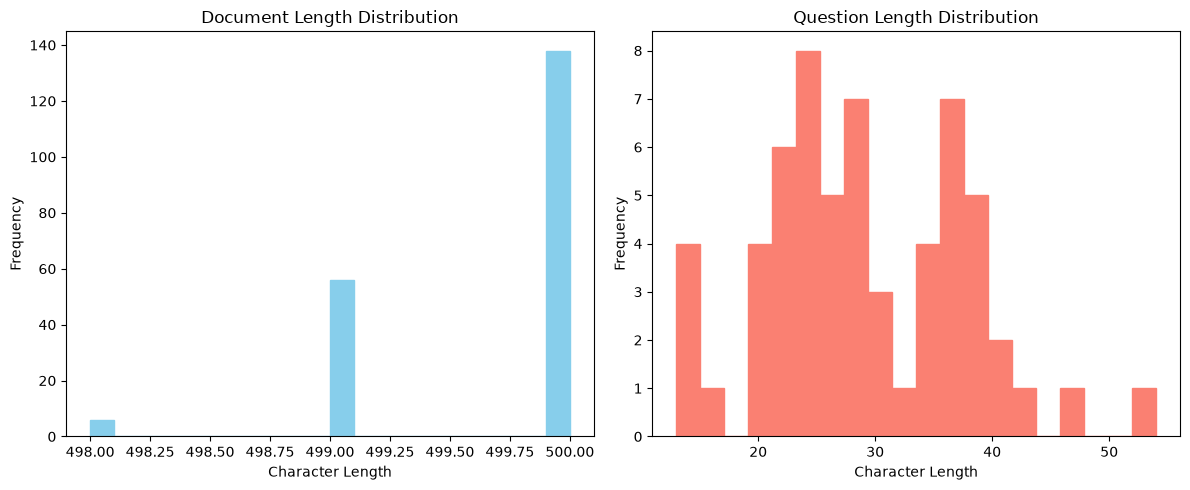

In [5]:
# [학생 구현] CP-01 — 데이터 길이 분석 및 시각화
corpus_stats = corpus_df.copy()
valid_stats = valid_df.copy()
# TODO 1-1. corpus_stats['char_length']에 문서 text의 글자 수를 계산해 넣으세요.
corpus_stats['char_length'] = corpus_stats['text'].str.len()
# TODO 1-2. valid_stats['char_length']에 질문 question의 글자 수를 계산해 넣으세요.
valid_stats['char_length'] = valid_stats['question'].str.len()
# TODO 1-3. describe()로 문서·질문 길이 통계를 출력하세요.
print("--- 문서통계 --- \n", corpus_stats['char_length'].describe())
print("--- 질문통계 --- \n", valid_stats['char_length'].describe())
# TODO 1-4. 두 길이 분포를 histogram으로 시각화하고 FIGURES에 저장하세요.
#             matplotlib의 plt.subplots(), ax.hist(), fig.savefig()를 사용합니다.
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
plt.hist(corpus_stats['char_length'], bins=20, color='skyblue', edgecolor='skyblue')
plt.title('Document Length Distribution')
plt.xlabel('Character Length')
plt.ylabel('Frequency')
plt.subplot(1, 2, 2)
plt.hist(valid_stats['char_length'], bins=20, color='salmon', edgecolor='salmon')
plt.title('Question Length Distribution')
plt.xlabel('Character Length')
plt.ylabel('Frequency')
plt.tight_layout()
plt.savefig(FIGURES / 'length_distribution.png')  

# raise NotImplementedError('CP-01 길이 분석·그래프 TODO를 완성하세요.')


**질문–정답 문단 겹침 분석(공통).** TF-IDF는 질문과 문단에 같은 글자 묶음이 많이 나올수록 유리합니다. 질문의 글자 2개 묶음(2-gram) 가운데 정답 문단에도 나오는 비율을 질문마다 계산해 `valid_overlap`에 저장합니다. 겹침 비율이 낮은 질문은 문단과 다른 표현으로 물어본 질문입니다. 코드는 제공되며, 학생들은 표를 읽고 아래 기록을 작성합니다. 이 표는 CP-09에서 검색에 실패한 질문과 다시 비교합니다.

In [6]:
# [공통] CP-01 — 질문과 정답 문단의 글자 겹침 비율 (Validation 질문만 사용)

def char_bigrams(text):
    """어절 안에서 만든 글자 2개 묶음의 집합. 예: '검색 성능' → {'검색', '성능'}"""
    return {word[i:i + 2] for word in str(text).split() for i in range(len(word) - 1)}


def overlap_ratio(question, document):
    """질문의 글자 2-gram 중 문단에도 등장하는 비율(0~1)."""
    question_grams = char_bigrams(question)
    if not question_grams:
        return 0.0
    return len(question_grams & char_bigrams(document)) / len(question_grams)


_doc_text = corpus_df.set_index('doc_id')['text']
valid_overlap = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
valid_overlap['overlap'] = [overlap_ratio(q, _doc_text[d])
                            for q, d in zip(valid_overlap['question'], valid_overlap['relevant_doc_id'])]
print('질문–정답 문단 겹침 비율 통계:')
display(valid_overlap['overlap'].describe().to_frame('겹침 비율').round(3))
print('겹침 비율이 가장 낮은 질문 5개:')
display(valid_overlap.sort_values('overlap').head(5)[['query_id', 'question', 'overlap']].round(3))
valid_overlap.to_csv(TABLES / 'cp01_validation_overlap.csv', index=False, encoding='utf-8-sig')

질문–정답 문단 겹침 비율 통계:


,겹침 비율
count,60.000
mean,0.474
std,0.175
min,0.158
25%,0.333
50%,0.462
75%,0.601
max,0.882


겹침 비율이 가장 낮은 질문 5개:


,query_id,question,overlap
17,QV018,소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?,0.158
45,QV046,싸움에 대비한 체육을 다룬 교육의 명칭은?,0.167
51,QV052,한국전쟁은 남한이 일으켰다고 주장한 사람은?,0.200
50,QV051,누구나 쇼핑몰을 할 수 있게 된 것 같은 변화가 제조업에서도 일어날 수 있는 것은 ...,0.217
8,QV009,영국은 어느나라와의 싸움에서 승리해 코이누르 보석을 습득했나요?,0.227


In [7]:
low5 = valid_overlap.sort_values('overlap').head(5)      # 겹침이 가장 낮은 질문 5개
for row in low5.itertuples():
    print(row.query_id, '| 겹침', round(row.overlap, 3))
    print('질문:', row.question)
    print('정답 문단:', _doc_text[row.relevant_doc_id])   # 그 질문의 정답 문단 본문
    print('-' * 80)

QV018 | 겹침 0.158
질문: 소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?
정답 문단: ;현재의 세계
:마왕 헤트라슈바이켈 시대 이후 700년, 대륙은 수많은 국가가 전쟁을 벌이는 전국시대에 돌입한다. 이 혼란은 '천(天)의 여왕' 세라프 몰트 엘 크레이프의 등장과 함께 종식한다. 세계 유일의 황제가 된 세라프 몰트 엘 크레이프는 대륙 전체에 '마법금지정책'을 공표하게 된다.

;근대 소설
:한편, 문화의 시대가 된 현재에 염가판의 도서가 등장하고 서민들이 많은 책을 접하게 되면서 근대 소설의 시대가 열린다. '세레스 에레오르'라는 필명으로 쓴 '랑그라시아나의 밤'은 100만 부에 육박하는 판매 부수를 기록하는 큰 인기를 얻거나, 많은 양산형 문학이 등장하기도 한다. 본 작에서 서술되고 있는 근대 소설의 상황은 대한민국과 일본의 장르 문학의 현재 상황을 비유하고 있다.

;마장지
:대기 중의 마나가 고갈된 현재에 마법을 사용할 수 있는 수단으로, 이 종이에 마법식을 적어 마법을 사용할 수 있다. 마법금지정책으로 그 제조는 강력하게 규제되고 있다.

;카토르바슈 신성학원
--------------------------------------------------------------------------------
QV046 | 겹침 0.167
질문: 싸움에 대비한 체육을 다룬 교육의 명칭은?
정답 문단: 시민들이 서로 친분을 쌓았으며, 이는 굳건한 형제애를 형성하는 데에 도움이 된다.
* 시민들에게 자녀 부양 의무와 교육 의무를 부여했으며, 모든 시민의 자녀들에게 교육 혜택을 제공하였다. 교육은 생활 유지에 필수적인 사냥, 합리적 사고에 필수적인 논변학 및 수학과 전투에 도움이 되는 실전 체육이 주된 내용이었으며, 이를 아고게(agoge)라고 한다. 하지만, 장애가 있는 아이의 경우는 사회 효율성 증대에 도움이 되지 않는다는 이유로 죽이거나 내다 버리게 하였으며, 이 교육 과정에서 지향하는 과도한 경쟁성으로 인해 사망하는 아이들이 많

**[기록] 결과 해석 — CP-01**

- 문서 길이와 질문 길이 분포에서 관찰한 특징: **[직접 작성]**
문서 200개의 길이는 평균 약 500자이고 표준편차는 약 0.53자로, 거의 모두 498~500자로 일정하다. 반면 질문 60개의 길이는 평균 약 29자이며, 13~54자로 질문마다 차이가 있다. 문서와 질문의 길이가 많은 차이가 있고, 문서가 일정한 길이로 나뉘어 있어 문서 길이 차이의 영향은 작고, 질문에 담긴 표현과 핵심 단어의 차이가 검색 결과에 더 영향을 줄 수 있다.
- 질문–정답 문단 겹침 비율 분포에서 관찰한 특징: **[직접 작성]**
질문의 어절 내부 글자 2-gram이 정답 문단에도 나타나는 비율은 60개 질문에서 평균 0.474, 중앙값 0.462였다. 즉, 평균적으로 질문의 글자 2-gram 중 약 절반이 정답 문단에 포함되어 있었다. 다만 비율은 0.158~0.882로 편차가 컸고, 가운데 50%도 0.333~0.601 범위에 분포했다. 따라서 질문에 따라 정답 문단과의 표면적 문자열 겹침 정도가 상당히 다르며, 겹침이 낮은 질문은 단어 일치에 의존하는 검색이 어려울 수 있다.
- 가설 1 — TF-IDF가 잘 찾을 것으로 예상하는 질문과 이유: **[직접 작성]**
정답 문단과 글자 2-gram 겹침 비율이 높은 질문에서 TF-IDF 검색이 잘 작동할 것으로 예상한다. TF-IDF는 질문과 문서에 공통으로 등장하는 단어를 바탕으로 유사도를 계산하므로, 질문의 핵심 표현이나 고유명사가 정답 문단에도 나타나면 해당 문단의 점수가 높아질 수 있다. 반대로 겹침 비율이 낮은 질문은 정답 문단이 다른 표현을 사용했을 가능성이 있어 찾기 어려울 수 있다.
- 가설 2 — BERT 기반 검색에서 유리하거나 불리할 것 같은 질문과 이유: **[직접 작성]**
정답 문단과 글자 2-gram 겹침은 낮아도 질문과 문단이 의미상 비슷한 표현을 사용하는 경우, 문맥을 반영하는 BERT 기반 검색이 유리할 것으로 예상한다. 다만 BERT 임베딩 검색은 질문과 문단의 의미가 비슷한지를 찾는 방식이므로, 인물·사건의 정확한 관계나 부정 표현처럼 세부 조건이 중요한 질문에서는 주제만 비슷한 문단을 잘못 찾을 수 있다. 따라서 겹침 비율이 낮은 질문에서 BERT가 TF-IDF보다 항상 우수하다고 단정하기보다는, 두 검색 결과의 정답 문단 포함 여부를 비교해 확인해야 한다.

**[CP-01 완료 기준]** 문서·질문 길이 통계와 그래프를 만들고 겹침 비율 표를 확인한 뒤, 두 검색 방식의 예상 강점·한계를 기록합니다. **Test 질문은 열지 않습니다.**


---
## CP-02. TF-IDF 기반 기준 검색기 구현

TF-IDF는 이미 배운 전통적인 텍스트 표현 방법입니다. 이번에는 한국어 띄어쓰기의 영향을 줄이기 위해 **문자 2~3-gram TF-IDF**를 기준선으로 사용하고, 질문과 문단 간 유사도로 Top-k를 찾습니다.


**TF-IDF 검색기(학생 구현).** 문서 전체의 벡터를 만든 뒤 질문을 같은 TF-IDF 기준으로 변환합니다. 코사인 유사도에 따라 점수를 정렬하고, 앞에서부터 k개의 문서를 반환합니다.


In [8]:
# [학생 구현] CP-02 — TF-IDF + 공통 Top-k 정렬 함수
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# TODO 2-1. analyzer='char', ngram_range=(2, 3), max_features=30000인 TfidfVectorizer를
#           tfidf_vectorizer라는 이름으로 만드세요.
tfidf_vectorizer = TfidfVectorizer(analyzer='char', ngram_range=(2, 3), max_features=30000)
# TODO 2-2. Corpus의 text로 fit_transform()하여 tfidf_docs를 만드세요.
tfidf_docs = tfidf_vectorizer.fit_transform(corpus_df['text'])
print(tfidf_docs.shape)

def top_k_results(scores, frame, k=5):
    """점수가 높은 문서 k개를 반환합니다. 키: rank, doc_id, score, text"""
    scores = np.asarray(scores, dtype=np.float64).ravel()
    assert len(scores) == len(frame)
    k = min(max(1, int(k)), len(frame))
    # TODO 2-3. np.argsort(-scores)로 점수 내림차순 상위 k개 인덱스를 고르세요.
    top_k_ind = np.argsort(-scores)[:k]

    # TODO 2-4. 위 인덱스로 rank, doc_id, score, text 키를 이 순서대로 가진 딕셔너리 리스트를 반환하세요.
    #           rank는 1부터 시작합니다. 검증 셀이 키의 순서까지 확인합니다.
    results = []
    for rank, idx in enumerate(top_k_ind, start=1):
        results.append({
            'rank': rank,
            'doc_id': frame.iloc[idx]['doc_id'],
            'score': scores[idx],
            'text': frame.iloc[idx]['text']
        })

    #raise NotImplementedError('CP-02 Top-k 정렬을 구현하세요.')
    return results

def search_tfidf(query, k=5):
    # TODO 2-5. tfidf_vectorizer.transform()으로 질문을 벡터로 만드세요.
    query_vector = tfidf_vectorizer.transform([query])
    # TODO 2-6. cosine_similarity()로 전체 문서와의 점수를 계산하세요.
    scores = cosine_similarity(query_vector, tfidf_docs).ravel()
    # TODO 2-7. top_k_results()를 호출해 검색 결과를 반환하세요.
    # raise NotImplementedError('CP-02 TF-IDF 검색 함수를 구현하세요.')
    return top_k_results(scores, corpus_df, k)

# TODO 2-8. Validation 질문 하나로 상위 3개 문서를 출력해 보세요.
query = valid_df.iloc[0]['question']
results = search_tfidf(query, k=3)
for result in results:
    print(f"Rank: {result['rank']}, Doc ID: {result['doc_id']}, Score: {result['score']:.4f}")


(200, 30000)
Rank: 1, Doc ID: D015, Score: 0.1418
Rank: 2, Doc ID: D078, Score: 0.0697
Rank: 3, Doc ID: D175, Score: 0.0659


**TF-IDF 검색 검증(공통).** 점수가 가장 큰 문서가 첫 번째 결과로 반환되어야 합니다. 검색 함수가 `rank·doc_id·score·text`를 모두 반환해야 BERT 검색과 같은 평가기를 재사용할 수 있습니다.


In [9]:
# [공통 검증] CP-02
_demo_corpus = pd.DataFrame({'doc_id': ['A', 'B', 'C'], 'text': ['가', '나', '다']})
_demo_rank = top_k_results([0.2, 0.9, 0.4], _demo_corpus, 2)
assert [h['doc_id'] for h in _demo_rank] == ['B', 'C']
assert list(_demo_rank[0]) == ['rank', 'doc_id', 'score', 'text']
assert tfidf_docs.shape[0] == len(corpus_df)
_check = search_tfidf(valid_df.iloc[0]['question'], 5)
assert len(_check) == 5 and len(set(h['doc_id'] for h in _check)) == 5
print('CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료')


CP-02 통과: TF-IDF 검색과 Top-k 정렬 완료


**[CP-02 완료 기준]** TF-IDF 문서 행렬을 만들고 `search_tfidf(query, k)`가 유사도 내림차순의 결과를 반환하며 검증 셀을 통과합니다.


---
## CP-03. BERT Encoder 출력과 입력 Shape 분석

기존 KLUE-YNAT 뉴스 분류에서는 BERT 출력으로 분류했습니다. 이번에는 Classification Head가 아닌 **BERT Encoder의 토큰별 문맥 벡터(`last_hidden_state`)**를 문서 표현에 사용합니다.


**BERT 모델 로딩(공통).** `klue/bert-base`를 불러와 추론 모드로 전환합니다. 다운로드된 가중치는 `weights/`에 저장되므로 GPU 세션이 유지되는 동안 반복 다운로드하지 않습니다.


In [10]:
# [공통] CP-03 — BERT Encoder·Tokenizer 준비
from transformers import AutoTokenizer, AutoModel

BASE_MODEL = 'klue/bert-base'
MAX_LENGTH = 256
BATCH_SIZE = 16

tokenizer = AutoTokenizer.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS))
bert_model = AutoModel.from_pretrained(BASE_MODEL, cache_dir=str(WEIGHTS), use_safetensors=True)
bert_model = bert_model.to(DEVICE).eval()
print('BERT Encoder:', BASE_MODEL, '| hidden_size:', bert_model.config.hidden_size)


BERT Encoder: klue/bert-base | hidden_size: 768


**BERT 입력·출력 구조 확인(학생 구현).** 서로 다른 길이의 질문 두 개를 Batch로 묶고 `attention_mask`와 `last_hidden_state`의 Shape를 확인합니다. 토큰마다 벡터가 하나씩 있으므로 아직 문장 하나당 벡터 하나인 상태가 아님을 확인하세요.


In [11]:
# [학생 구현] CP-03 — 토큰 단위 문맥 벡터 확인
sample_questions = valid_df['question'].head(2).astype(str).tolist()
# TODO 3-1. tokenizer()로 질문 두 개를 padding/truncation하여 return_tensors='pt'로 만들고
#           inputs라는 이름으로 저장하세요.
inputs = tokenizer(sample_questions, padding=True, truncation=True, return_tensors='pt')
# TODO 3-2. 입력 Tensor를 DEVICE로 옮기세요.
inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

# TODO 3-3. torch.inference_mode() 안에서 bert_model(**inputs)를 실행하세요.
with torch.inference_mode():
    outputs = bert_model(**inputs)

# TODO 3-4. 출력의 last_hidden_state는 last_hidden, 입력의 attention_mask는 mask라는 이름으로 저장하고
#           두 Tensor의 Shape와 문장별 유효 토큰 수를 출력하세요.
# [주의] 다음 CP-04 셀이 last_hidden과 mask라는 이름을 그대로 사용합니다.
last_hidden = outputs.last_hidden_state
mask = inputs['attention_mask']
print(f"input_ids: {inputs['input_ids'].shape}")
print(f"Last Hidden State Shape: {last_hidden.shape}")
print(bert_model.config)
print(f"Attention Mask Shape: {mask.shape}")
print(f"Valid Tokens per Sentence: {mask.sum(dim=1).tolist()}")
# raise NotImplementedError('CP-03 BERT Encoder의 입력·출력 Shape를 확인하세요.')


input_ids: torch.Size([2, 19])
Last Hidden State Shape: torch.Size([2, 19, 768])
BertConfig {
  "architectures": [
    "BertForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "classifier_dropout": null,
  "dtype": "float32",
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "layer_norm_eps": 1e-12,
  "max_position_embeddings": 512,
  "model_type": "bert",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 0,
  "position_embedding_type": "absolute",
  "transformers_version": "4.57.6",
  "type_vocab_size": 2,
  "use_cache": true,
  "vocab_size": 32000
}

Attention Mask Shape: torch.Size([2, 19])
Valid Tokens per Sentence: [15, 19]


**[기록] 결과 해석 — CP-03**

- `last_hidden_state`의 세 차원(Batch·Token·Hidden)이 각각 의미하는 것: **[직접 작성]**
last_hidden_state의 shape은 (Batch, Token, Hidden)입니다. Batch는 한 번에 처리하는 문장 수, Token은 각 문장이 토큰화된 길이, Hidden은 각 토큰을 표현하는 벡터의 차원 수입니다. 예를 들어 shape이 (2, 19, 768)이면 문장 2개를 처리하고, 문장마다 최대 19개 토큰이 있으며, 각 토큰을 768차원 벡터로 나타낸 것입니다.
- `attention_mask`가 0인 위치를 평균에서 제외해야 하는 이유: **[직접 작성]**
마스크가 0인 위치는 문장을 같은 길이로 맞추기 위해 추가된 패딩 토큰입니다. 패딩 벡터까지 평균에 포함하면 실제 문장 내용과 관계없는 값이 문장 벡터에 섞여 표현이 왜곡될 수 있습니다. 따라서 마스크가 1인 실제 토큰만 평균에 포함합니다.

**[CP-03 완료 기준]** BERT Encoder 출력 Shape·Attention Mask를 직접 확인하고, 토큰 표현과 문장 표현의 차이를 기록합니다.


---
## CP-04. Attention Mask 기반 Mean Pooling 구현

BERT는 토큰마다 벡터 하나를 출력하지만 검색에서는 **질문 1개·문단 1개를 각각 하나의 벡터**로 표현해야 합니다. 패딩 위치를 제외하고 유효 토큰 벡터만 평균내는 함수를 구현합니다.


**Masked Mean Pooling(학생 구현).** Attention Mask를 `(B, T, 1)`로 바꾸어 토큰별 벡터에 곱합니다. 유효 토큰 벡터의 합을 유효 토큰 수로 나누되, 0으로 나누는 경우는 방지합니다.


In [12]:
# [학생 구현] CP-04 — Masked Mean Pooling

def mean_pooling(last_hidden_state, attention_mask):
    """(B,T,H)+(B,T) → (B,H), 패딩 제외 토큰 평균."""
    # TODO 4-1. 패딩 위치의 벡터가 평균에 들어가지 않도록, attention_mask를 토큰 벡터와 곱할 수 있는
    #           모양 (B,T,1)로 바꾸세요.
    attention_mask = attention_mask.unsqueeze(-1).to(last_hidden_state.dtype)  # (B,T) -> (B,T,1)
    # TODO 4-2. 토큰 벡터에 mask를 적용해 패딩 위치의 벡터를 0으로 만드세요.
    last_hidden_state = last_hidden_state * attention_mask
    # TODO 4-3. 토큰 축(T)을 따라 벡터를 합해 문장마다 벡터 하나 (B,H)가 되게 하세요.
    sentence_vecs = last_hidden_state.sum(dim=1)
    # TODO 4-4. 문장별 유효 토큰 수로 나누어 평균 (B,H)를 반환하세요.
    #           유효 토큰 수가 0인 경우에도 0으로 나누지 않도록 처리합니다.
    # raise NotImplementedError('CP-04 Masked Mean Pooling을 구현하세요.')
    valid_token_counts = attention_mask.sum(dim=1).clamp(min=1)
    sentence_vecs = sentence_vecs / valid_token_counts
    return sentence_vecs

sentence_vecs = mean_pooling(last_hidden, mask)
print('Pooling 후:', tuple(sentence_vecs.shape))


Pooling 후: (2, 768)


**Pooling 숫자 검증(공통).** 마지막 토큰에 매우 큰 숫자가 들어 있어도 `attention_mask=0`이면 평균에 포함되면 안 됩니다. 아래 검증 셀은 실제 BERT 가중치 없이 작은 Tensor만으로 정답을 확인합니다.


In [13]:
# [공통 검증] CP-04 — Padding을 제외한 평균
_toy_hidden = torch.tensor([[[1., 0.], [3., 2.], [100., 100.]],
                            [[2., 4.], [20., 20.], [40., 40.]]])
_toy_mask = torch.tensor([[1, 1, 0], [1, 0, 0]])
_toy_out = mean_pooling(_toy_hidden, _toy_mask)
print(_toy_out.shape)
assert _toy_out.shape == (2, 2)
assert torch.allclose(_toy_out, torch.tensor([[2., 1.], [2., 4.]]), atol=1e-6)
assert sentence_vecs.shape == (2, bert_model.config.hidden_size)
print('CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인')


torch.Size([2, 2])
CP-04 통과: Padding 제외 평균과 (Batch, Hidden) Shape 확인


**[CP-04 완료 기준]** `mean_pooling()`을 완성하고 유효 토큰만 평균을 낸 검증을 통과합니다. **생각해 볼 질문:** `attention_mask`를 무시하면 문장 길이에 따른 패딩이 검색 결과에 어떤 영향을 줄까요?


---
## CP-05. BERT 문서 임베딩과 코사인 유사도 계산

문서 200개를 BERT Encoder와 Pooling을 통과시켜 같은 차원의 벡터로 변환합니다. 질문 벡터와 각 문서 벡터의 **코사인 유사도**를 직접 계산합니다.


**BERT 임베딩 Batch 처리(학생 구현).** 문서를 한 번에 모두 처리하면 메모리를 많이 사용하므로 16개씩 Tokenizer → BERT → Mean Pooling을 반복합니다. 결과는 NumPy 배열로 합치며, 이후 GPU를 다시 사용하지 않도록 저장합니다.


In [14]:
# [학생 구현] CP-05 — BERT 임베딩 생성 함수

def encode_bert_texts(texts, batch_size=BATCH_SIZE):
    """문장/문단 리스트 → (N, Hidden) NumPy 배열."""
    texts = [str(t) for t in texts]
    vectors = []
    for start in range(0, len(texts), batch_size):
        batch = texts[start:start + batch_size]
        # TODO 5-1. batch를 tokenizer()로 Tensor로 변환하고 DEVICE로 옮기세요.
        encoded = tokenizer(batch, padding=True, truncation=True, return_tensors='pt').to(DEVICE)
        # TODO 5-2. 추론 모드에서 bert_model(**encoded)로 last_hidden_state를 얻으세요.
        with torch.no_grad():
            last_hidden = bert_model(**encoded).last_hidden_state
        # TODO 5-3. mean_pooling()을 적용하고 CPU NumPy 배열로 vectors에 추가하세요.
        # raise NotImplementedError('CP-05 BERT Batch 임베딩 계산을 구현하세요.')
        sentence_vecs = mean_pooling(last_hidden, encoded['attention_mask'])
        vectors.append(sentence_vecs.detach().cpu().numpy())
    return np.vstack(vectors) if vectors else np.empty((0, bert_model.config.hidden_size))


def cosine_scores(query_vector, document_matrix):
    """질문 벡터 (H,)와 문서 행렬 (N,H) → 유사도 (N,)."""
    query_vector = np.asarray(query_vector, dtype=np.float64).reshape(-1)
    document_matrix = np.asarray(document_matrix, dtype=np.float64)
    # TODO 5-4. 질문 벡터와 각 문서 벡터의 내적을 구하세요. 결과는 문서 수만큼의 값 (N,)입니다.
    dot_product = np.dot(document_matrix, query_vector)
    # TODO 5-5. 질문 벡터의 크기(노름)와 각 문서 벡터의 크기를 구하세요.
    query_norm = np.linalg.norm(query_vector)
    document_norms = np.linalg.norm(document_matrix, axis=1)
    denominator = query_norm * document_norms
    # TODO 5-6. 내적을 두 크기의 곱으로 나눈 코사인 유사도 배열 (N,)을 반환하세요.
    #           분모가 0이 되는 경우에도 오류가 나지 않도록 처리합니다.
    # raise NotImplementedError('CP-05 코사인 유사도를 구현하세요.')
    denominator = np.where(denominator == 0, 1e-10, denominator)  # 분모가 0인 경우 작은 값으로 대체
    cosine_similarity = dot_product / denominator
    return cosine_similarity

**문서 임베딩 캐싱(공통).** `bert_corpus_200_256.npy`가 이미 있으면 다시 계산하지 않습니다. 다만 저장된 벡터가 **지금의 `encode_bert_texts()`가 계산한 결과와 같은지** 앞 문서 4개로 먼저 확인합니다. 함수를 고친 뒤라서 결과가 다르면 전체를 다시 계산해 덮어쓰므로, 예전에 잘못 계산된 벡터가 계속 쓰이지 않습니다.

In [15]:
# [공통] CP-05 — BERT Corpus 임베딩 생성/재사용
BERT_DOC_CACHE = CACHE / 'bert_corpus_200_256.npy'


def load_or_encode(cache_file, texts, n_check=4):
    """저장된 임베딩이 현재 encode_bert_texts()의 결과와 같을 때만 재사용합니다.

    앞 n_check개를 다시 계산해 저장본과 비교하고, 다르면(함수를 고친 경우 등) 전체를 다시 계산해 덮어씁니다.
    """
    texts = [str(t) for t in texts]
    expected_shape = (len(texts), bert_model.config.hidden_size)
    if cache_file.is_file():
        cached = np.load(cache_file)
        if cached.shape == expected_shape:
            fresh = encode_bert_texts(texts[:n_check])
            if fresh.shape == cached[:n_check].shape and np.allclose(fresh, cached[:n_check], atol=1e-3):
                print('저장된 임베딩 재사용:', cache_file.name)
                return cached
        print('저장된 임베딩이 현재 함수의 결과와 달라 다시 계산합니다:', cache_file.name)
    vectors = encode_bert_texts(texts)
    np.save(cache_file, vectors)
    return vectors


bert_doc_vectors = load_or_encode(BERT_DOC_CACHE, corpus_df['text'].tolist())
print('BERT 문서 벡터 Shape:', bert_doc_vectors.shape)

저장된 임베딩 재사용: bert_corpus_200_256.npy
BERT 문서 벡터 Shape: (200, 768)


**코사인 유사도 검증(공통).** 질문과 같은 방향의 문서 벡터는 유사도가 1에 가까워야 합니다. 문서가 200개이므로 질문 하나에 대한 점수 배열도 반드시 길이 200이어야 합니다.


In [16]:
# [공통 검증] CP-05
_test_scores = cosine_scores(np.array([1., 0.]),
                             np.array([[1., 0.], [0., 1.], [-1., 0.]]))
assert np.allclose(_test_scores, [1., 0., -1.], atol=1e-6)
assert bert_doc_vectors.shape == (200, bert_model.config.hidden_size)
assert np.isfinite(bert_doc_vectors).all()
print('CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상')


CP-05 통과: 코사인 유사도 및 BERT 문서 임베딩 정상


**[CP-05 완료 기준]** BERT 임베딩 (200, 768) 배열을 저장하고, 직접 작성한 `cosine_scores()`가 숫자 검증을 통과합니다.


---
## CP-06. Top-k BERT 문서 검색기 완성

이제 질문을 같은 BERT Encoder로 벡터화하고 저장된 문서 벡터들과 비교합니다. CP-02에서 구현한 `top_k_results()`를 재사용해 **검색기가 하나의 완성된 프로그램**으로 동작하도록 연결합니다.


**BERT 검색 함수(학생 구현).** 질문 하나를 BERT 임베딩으로 변환해 문서 200개와 코사인 유사도를 계산합니다. 상위 k개 결과의 문서 ID, 유사도, 원문을 같은 인터페이스로 반환해야 Day 2에서 두 검색기를 공정하게 평가할 수 있습니다.


In [17]:
# [학생 구현] CP-06 — BERT 검색 함수
bert_query_cache = {}  # Day 2에 일괄 준비할 검색 질문 벡터 캐시

def search_bert(query, k=5):
    query = str(query)
    # TODO 6-1. 캐시에 query가 있다면 재사용하고, 없다면 encode_bert_texts([query])[0]를 사용하세요.
    if query in bert_query_cache:
        query_vector = bert_query_cache[query]
    else:
        query_vector = encode_bert_texts([query])[0]
        bert_query_cache[query] = query_vector
    # TODO 6-2. cosine_scores()로 corpus 전체 문서와의 점수를 구하세요.
    scores = cosine_scores(query_vector, bert_doc_vectors)
    # TODO 6-3. top_k_results()를 호출하여 상위 k개의 검색 결과를 반환하세요.
    #raise NotImplementedError('CP-06 BERT 검색 함수를 구현하세요.')
    return top_k_results(scores, corpus_df, k)

# TODO 6-4. Validation 질문 하나를 골라 BERT 검색 결과 Top-3를 표로 확인하세요.
query = valid_df.iloc[0]['question']
results = search_bert(query, k=3)
for result in results:
    print(f"Rank: {result['rank']}, Doc ID: {result['doc_id']}, Score: {result['score']:.4f}")


Rank: 1, Doc ID: D015, Score: 0.6945
Rank: 2, Doc ID: D124, Score: 0.6452
Rank: 3, Doc ID: D068, Score: 0.6409


**검색기 출력 검증(공통).** 두 검색 방식이 반환하는 항목과 순위 형식이 동일한지 확인합니다. 단위 테스트는 검색 결과의 구조만 확인하며, 이 단계에서 검색 점수가 높아야 한다는 조건을 요구하지 않습니다.


In [18]:
# [공통 검증] CP-06
_question = valid_df.iloc[0]['question']
for _search_fn in [search_tfidf, search_bert]:
    _hits = _search_fn(_question, 3)
    assert len(_hits) == 3 and [h['rank'] for h in _hits] == [1, 2, 3]
    assert all({'doc_id', 'text', 'score'} <= set(h) for h in _hits)
    assert _hits[0]['score'] >= _hits[1]['score'] >= _hits[2]['score']
print('CP-06 통과: TF-IDF / BERT Top-k 검색기 완성')


CP-06 통과: TF-IDF / BERT Top-k 검색기 완성


**[Day 1 완료 기준]** 문서 분석과 검색 성능 가설, TF-IDF 검색기, BERT Masked Mean Pooling, 코사인 유사도, `search_bert()`와 검증 셀을 모두 완료합니다. **Day 1 종료 후 작성한 Notebook을 GitHub에 저장하세요.**


# Day 2 — 검색 성능 평가·오류 분석·최종 검색 방식 선정

둘째 날은 `CP-07~10`을 진행합니다. **Validation 질문에서만 모델을 비교하고 선택**한 후, 보류 Test 질문은 CP-10의 최종 평가에 사용합니다.

---
## CP-07. 검색 평가 함수 구현 — Hit@1 · Recall@3 · MRR@5

분류에서 Accuracy·F1을 계산했던 것처럼 문서 검색에도 평가 기준이 필요합니다. 이번에는 질문마다 **정답 문서가 하나**이므로, 그 문서가 몇 위에 검색되었는지로 성능을 평가합니다.


**검색 평가 지표 구현(학생 구현).** Hit@1은 정답 문서가 첫 번째인지, Recall@3은 상위 3개에 있는지, MRR@5는 상위 5개 안에서의 정답 순위 역수입니다. 질문별 지표를 평균하여 전체 검색 성능을 계산합니다.


In [19]:
# [학생 구현] CP-07 — 검색 평가 지표

def retrieval_metrics(hits, relevant_doc_id):
    """하나의 정답 문서 기준 Hit@1·Recall@3·MRR@5·rank 반환."""
    doc_ids = [h['doc_id'] for h in hits]
    # TODO 7-1. relevant_doc_id가 doc_ids에 있으면 순위(1부터 시작)를 구하세요. 없으면 None.
    rank = None
    if relevant_doc_id in doc_ids:
        rank = doc_ids.index(relevant_doc_id) + 1

    # TODO 7-2. Hit@1, Recall@3, MRR@5를 각각 계산해
    #             {'hit1': ..., 'recall3': ..., 'mrr5': ..., 'rank': ...} 형태의 딕셔너리로 반환하세요.
    #             rank에는 7-1에서 구한 순위(없으면 None)를 넣습니다. CP-09에서 이 키 이름을 그대로 사용합니다.
    #             정답이 상위 5개에 없으면 MRR@5는 0입니다.
    # raise NotImplementedError('CP-07 검색 평가 지표를 구현하세요.')
    hit1 = 1 if rank == 1 else 0
    recall3 = 1 if rank is not None and rank <= 3 else 0
    mrr5 = 1 / rank if rank is not None and rank <= 5 else 0
    return {'hit1': hit1, 'recall3': recall3, 'mrr5': mrr5, 'rank': rank}

def evaluate_search(search_fn, questions_df):
    """질문 데이터 전체 검색 결과: (summary_dict, detail_DataFrame)."""
    rows = []
    for row in questions_df.itertuples(index=False):
        # TODO 7-3. search_fn(row.question, 5)를 호출하세요.
        hits = search_fn(row.question, 5)
        # print("hits: ", hits)
        # TODO 7-4. retrieval_metrics()로 정답 문서 순위·지표를 계산하세요.
        eval_metrics = retrieval_metrics(hits, row.relevant_doc_id)
        # print(eval_metrics)

        # TODO 7-5. query_id, question, relevant_doc_id, hit1, recall3, mrr5, rank, top1_doc_id를
        #           키로 가진 딕셔너리를 rows에 추가하세요.
        #raise NotImplementedError('CP-07 평가 데이터셋 반복을 구현하세요.')
        rows.append({
            'query_id': row.query_id,
            'question': row.question,
            'relevant_doc_id': row.relevant_doc_id,
            **eval_metrics,
            'top1_doc_id': hits[0]['doc_id'] if hits else None
        })
    detail = pd.DataFrame(rows)
    # TODO 7-6. hit1/recall3/mrr5 평균을 summary 딕셔너리로 만들고 (summary, detail)을 반환하세요.
    #raise NotImplementedError('CP-07 전체 평균 지표를 계산하세요.')
    summary = {
        'hit1': detail['hit1'].mean(),
        'recall3': detail['recall3'].mean(),
        'mrr5': detail['mrr5'].mean()
    }
    return summary, detail

**평가 지표 검증(공통).** 정답이 2위라면 Hit@1=0, Recall@3=1, MRR@5=0.5가 되어야 합니다. 먼저 작은 예제를 통과시킨 뒤 실제 Validation 질문 전체에 적용합니다.


In [20]:
# [공통 검증] CP-07
_toy_hits = [{'doc_id': 'A'}, {'doc_id': 'B'}, {'doc_id': 'C'},
             {'doc_id': 'D'}, {'doc_id': 'E'}]
_m = retrieval_metrics(_toy_hits, 'B')
assert _m['hit1'] == 0 and _m['recall3'] == 1 and np.isclose(_m['mrr5'], 0.5)
assert retrieval_metrics(_toy_hits, 'A')['hit1'] == 1
assert retrieval_metrics(_toy_hits, 'Z')['mrr5'] == 0
print('CP-07 검색 지표 단위 테스트 통과')


CP-07 검색 지표 단위 테스트 통과


**Validation 질문 임베딩 캐시(공통).** BERT 질문을 한 번에 Batch로 임베딩하여 CP-07~09의 반복 평가에서 재사용합니다. 캐시를 준비한 뒤 TF-IDF와 BERT의 실제 Validation 성능을 계산합니다.


In [21]:
# [공통] CP-07 — 질문 벡터 일괄 계산 및 기준 성능 측정
BERT_VALID_CACHE = CACHE / 'bert_validation_60_256.npy'
# ### CP-05의 load_or_encode()로, 저장본이 현재 함수의 결과와 같을 때만 재사용합니다.
valid_bert_vecs = load_or_encode(BERT_VALID_CACHE, valid_df['question'].tolist())
bert_query_cache.update({str(q): vec for q, vec in
                         zip(valid_df['question'].tolist(), valid_bert_vecs)})

tfidf_summary, tfidf_detail = evaluate_search(search_tfidf, valid_df)
bert_summary, bert_detail = evaluate_search(search_bert, valid_df)
print('TF-IDF:', tfidf_summary)
print('BERT:', bert_summary)
print(bert_summary)
assert len(tfidf_detail) == len(bert_detail) == len(valid_df)


저장된 임베딩 재사용: bert_validation_60_256.npy
TF-IDF: {'hit1': np.float64(0.8833333333333333), 'recall3': np.float64(0.9666666666666667), 'mrr5': np.float64(0.9166666666666666)}
BERT: {'hit1': np.float64(0.6666666666666666), 'recall3': np.float64(0.85), 'mrr5': np.float64(0.7541666666666667)}
{'hit1': np.float64(0.6666666666666666), 'recall3': np.float64(0.85), 'mrr5': np.float64(0.7541666666666667)}


**[CP-07 완료 기준]** 세 가지 지표의 단위 테스트를 통과하고, TF-IDF와 BERT의 Validation Hit@1·Recall@3·MRR@5를 계산합니다.


---
## CP-08. TF-IDF·BERT·Sentence-BERT 검색 성능 비교

일반 BERT의 Mean Pooling은 검색 작업에 맞춰 학습된 문장 임베딩과 다를 수 있습니다. 한국어 문장 유사도 모델을 추가하고 세 검색 방식의 실제 Validation 결과를 비교합니다.


**한국어 Sentence-BERT 준비(공통).** `snunlp/KR-SBERT-V40K-klueNLI-augSTS`를 이용해 문서 벡터를 생성합니다. 이미 계산한 문서·질문 임베딩이 있으면 저장된 `.npy` 파일을 사용하며, 별도의 Fine-tuning은 하지 않습니다.


In [22]:
# [공통] CP-08 — Sentence-BERT 문서/질문 임베딩 준비
from sentence_transformers import SentenceTransformer

SBERT_MODEL = 'snunlp/KR-SBERT-V40K-klueNLI-augSTS'
sbert_model = SentenceTransformer(SBERT_MODEL, device=str(DEVICE), cache_folder=str(WEIGHTS))
# ### 기본 BERT와 비교할 때 문서가 잘리는 최대 토큰 길이를 통일합니다.
sbert_model.max_seq_length = MAX_LENGTH
SBERT_DOC_CACHE = CACHE / 'sbert_corpus_200.npy'
SBERT_VALID_CACHE = CACHE / 'sbert_validation_60.npy'

if SBERT_DOC_CACHE.is_file():
    sbert_doc_vectors = np.load(SBERT_DOC_CACHE)
else:
    sbert_doc_vectors = sbert_model.encode(corpus_df['text'].tolist(), batch_size=16,
                                            normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_DOC_CACHE, sbert_doc_vectors)
if SBERT_VALID_CACHE.is_file():
    sbert_valid_vectors = np.load(SBERT_VALID_CACHE)
else:
    sbert_valid_vectors = sbert_model.encode(valid_df['question'].tolist(), batch_size=16,
                                              normalize_embeddings=True, convert_to_numpy=True)
    np.save(SBERT_VALID_CACHE, sbert_valid_vectors)
assert len(sbert_doc_vectors) == len(corpus_df)
assert len(sbert_valid_vectors) == len(valid_df)
sbert_query_cache = {str(q): v for q, v in zip(valid_df['question'], sbert_valid_vectors)}
print('SBERT 문서 벡터:', sbert_doc_vectors.shape)

print("BERT 한계:", bert_model.config.max_position_embeddings)
print("토크나이저 한계:", tokenizer.model_max_length)
print("SBERT 입력 길이:", sbert_model.max_seq_length)

SBERT 문서 벡터: (200, 768)
BERT 한계: 512
토크나이저 한계: 512
SBERT 입력 길이: 256


**세 가지 검색 방식 비교(학생 구현).** Sentence-BERT 검색 함수를 작성하고 앞에서 만든 `evaluate_search()`로 동일한 Validation 질문을 평가합니다. 세 방식의 지표를 하나의 DataFrame과 막대그래프로 정리하세요.


sbert_summary {'hit1': np.float64(0.7666666666666667), 'recall3': np.float64(0.8833333333333333), 'mrr5': np.float64(0.8208333333333333)}


,hit1,recall3,mrr5
tfidf,0.883,0.967,0.917
bert,0.667,0.850,0.754
sbert,0.767,0.883,0.821


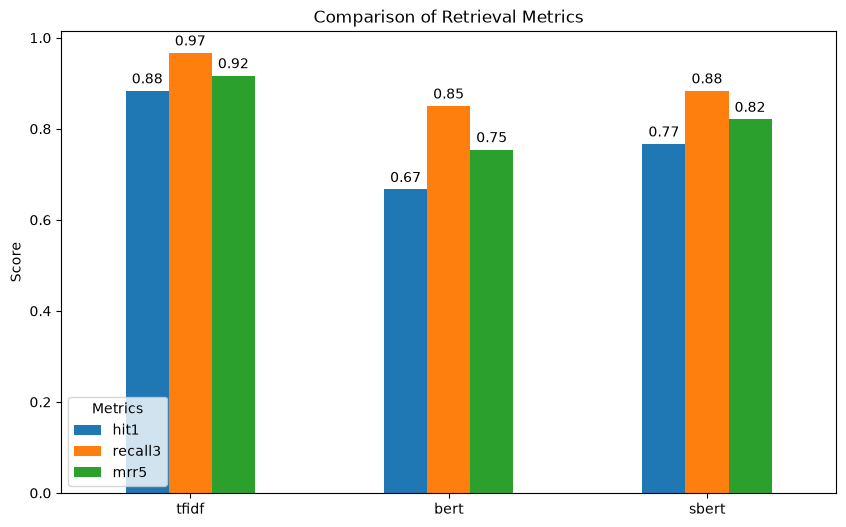

In [32]:
# [학생 구현] CP-08 — Sentence-BERT 검색 + 성능 비교

def search_sbert(query, k=5):
    query = str(query)
    # TODO 8-1. sbert_query_cache에 query가 있으면 캐시를, 없으면 sbert_model.encode()를 사용하세요.
    if query in sbert_query_cache:
        query_vector = sbert_query_cache[query]
    else:
        query_vector = sbert_model.encode([query], normalize_embeddings=True, convert_to_numpy=True)[0]
        sbert_query_cache[query] = query_vector

    # TODO 8-2. 질문 벡터와 sbert_doc_vectors의 코사인 유사도를 계산하고 top_k_results()로 검색 결과를 반환하세요.
    # raise NotImplementedError('CP-08 SBERT 검색을 구현하세요.')
    scores = cosine_scores(query_vector, sbert_doc_vectors)
    return top_k_results(scores, corpus_df, k)

# TODO 8-3. evaluate_search(search_sbert, valid_df)로 SBERT Validation을 평가하고
#           결과를 sbert_summary, sbert_detail이라는 이름으로 받으세요.
sbert_summary, sbert_detail = evaluate_search(search_sbert, valid_df)
print("sbert_summary", sbert_summary)
# TODO 8-4. tfidf_summary, bert_summary, sbert_summary를 comparison_df로 만드세요.
#             행: tfidf, bert, sbert / 열: hit1, recall3, mrr5
comparison_df = pd.DataFrame({
    'hit1': [tfidf_summary['hit1'], bert_summary['hit1'], sbert_summary['hit1']],
    'recall3': [tfidf_summary['recall3'], bert_summary['recall3'], sbert_summary['recall3']],
    'mrr5': [tfidf_summary['mrr5'], bert_summary['mrr5'], sbert_summary['mrr5']]
}, index=['tfidf', 'bert', 'sbert'])
display(comparison_df.round(3))

# TODO 8-5. comparison_df를 cp08_validation_comparison.csv로 저장하고 막대그래프를 그리세요.
# raise NotImplementedError('CP-08 세 검색 방식의 성능을 비교하세요.')
comparison_df.to_csv(TABLES / 'cp08_validation_comparison.csv', index=True, encoding='utf-8-sig')
ax = comparison_df.plot(kind='bar', figsize=(10, 6))

plt.title('Comparison of Retrieval Metrics')
plt.ylabel('Score')
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=3)
plt.xticks(rotation=0)
plt.legend(title='Metrics')


**비교 결과 검증(공통).** 세 검색기의 검색 결과 형식이 같고 지표가 0~1 사이인지 확인합니다. 성능의 순위는 데이터에 따라 달라지므로 BERT나 Sentence-BERT가 무조건 높아야 한다는 조건은 없습니다.


In [24]:
# [공통 검증] CP-08
assert comparison_df.index.tolist() == ['tfidf', 'bert', 'sbert']
assert (comparison_df[['hit1', 'recall3', 'mrr5']] >= 0).all().all()
assert (comparison_df[['hit1', 'recall3', 'mrr5']] <= 1).all().all()
assert len(sbert_detail) == len(valid_df)
assert search_sbert(valid_df.iloc[0]['question'], 3)[0]['rank'] == 1
print('CP-08 통과: 세 검색 방식의 Validation 평가 완료')


CP-08 통과: 세 검색 방식의 Validation 평가 완료


**[기록] 결과 해석 — CP-08**

- 세 검색기의 Hit@1·Recall@3·MRR@5 차이: **[실제 수치와 함께 작성]**
'hit1': np.float64(0.7666666666666667), 'recall3': np.float64(0.8833333333333333), 'mrr5': np.float64(0.8208333333333333)
- 예상과 다른 결과가 있다면 가능 원인: **[직접 작성]**

**[CP-08 완료 기준]** 세 방식의 동일 Validation 질문 비교표·그래프와 결과 해석을 완성합니다.


---
## CP-09. 검색 실패 사례 분석 및 최종 검색 방식 선정

성능 지표가 비슷하더라도 어떤 질문을 잘 찾고, 어떤 질문에서 실패하는지는 다를 수 있습니다. CP-01에서 세운 가설을 실제 Validation 검색 오류와 비교한 뒤 활용 목적에 맞는 검색 방식을 직접 선택합니다.


**검색 실패 질의 분석(학생 구현).** 세 검색기의 질문별 Hit@1을 합쳐 실패한 질문을 5개 이상 선정합니다. 세 검색기의 상위 문서와 정답 문서 ID를 나란히 비교하고 오류 원인을 기록합니다.


In [25]:
# [학생 구현] CP-09 — 질문별 성공/실패 비교 및 대표 오류 선택
error_df = valid_df[['query_id', 'question', 'relevant_doc_id']].copy()
# TODO 9-1. tfidf_detail, bert_detail, sbert_detail을 query_id로 병합하세요.
#             각 모델의 hit1/recall3/rank에는 모델 이름 접두사를 붙이세요.
error_df = error_df.merge(tfidf_detail[['query_id', 'hit1', 'recall3', 'rank']], on='query_id', suffixes=('', '_tfidf'))
error_df = error_df.merge(bert_detail[['query_id', 'hit1', 'recall3', 'rank']], on='query_id', suffixes=('', '_bert'))
error_df = error_df.merge(sbert_detail[['query_id', 'hit1', 'recall3', 'rank']], on='query_id', suffixes=('', '_sbert'))

# TODO 9-2. num_top1_failures = 3 - 세 모델의 hit1 합계를 계산하세요.
error_df['num_top1_failures'] = 3 - (error_df['hit1'] + error_df['hit1_bert'] + error_df['hit1_sbert'])

# TODO 9-3. 실패가 많은 질문 상위 5개를 error_cases로 추출해 표로 출력하세요.
error_cases = error_df.sort_values('num_top1_failures', ascending=False).head(5)
display(error_cases)

# TODO 9-4. 질문 하나에 대한 세 검색기의 Top-3 doc_id·유사도를 출력하세요.
query_id = error_cases.iloc[0]['query_id']
query_text = valid_df.loc[valid_df['query_id'] == query_id, 'question'].values[0]
print(f"Query ID: {query_id}, Question: {query_text}")
print("TF-IDF Top-3:")
tfidf_hits = search_tfidf(query_text, k=3)
for hit in tfidf_hits:
    print(f"Rank: {hit['rank']}, Doc ID: {hit['doc_id']}, Score: {hit['score']:.4f}")
print("BERT Top-3:")
bert_hits = search_bert(query_text, k=3)
for hit in bert_hits:
    print(f"Rank: {hit['rank']}, Doc ID: {hit['doc_id']}, Score: {hit['score']:.4f}")
print("SBERT Top-3:")
sbert_hits = search_sbert(query_text, k=3)
for hit in sbert_hits:
    print(f"Rank: {hit['rank']}, Doc ID: {hit['doc_id']}, Score: {hit['score']:.4f}")

# TODO 9-5. error_cases를 TABLES/'cp09_error_cases.csv'에 저장하세요.
# [힌트] CP-01의 valid_overlap[['query_id', 'overlap']]을 query_id로 병합해 두면
#        실패한 질문의 겹침 비율을 함께 볼 수 있습니다.
#raise NotImplementedError('CP-09 검색 실패 사례를 비교하세요.')
error_cases = error_cases.merge(valid_overlap[['query_id', 'overlap']], on='query_id', how='left')
error_cases.to_csv(TABLES / 'cp09_error_cases.csv', index=False, encoding='utf-8-sig')

display(error_cases)

error_df_overlap = error_df.merge(valid_overlap[['query_id', 'overlap']], on='query_id', how='left')
err_over_rank10 = error_df_overlap.sort_values('overlap', ascending=True).head(10)
display(f"겸침율이 낮은 순서: ", err_over_rank10)
err_over_rank10 = error_df_overlap.sort_values('overlap', ascending=False).head(10)
display(f"겹침율이 높은 순서: ", err_over_rank10)

,query_id,question,relevant_doc_id,hit1,recall3,rank,hit1_bert,recall3_bert,rank_bert,hit1_sbert,recall3_sbert,rank_sbert,num_top1_failures
19,QV020,소넨이 상을 받았던 해는?,D138,0,0,NaN,0,0,NaN,0,0,NaN,3
46,QV047,자바 API를 개발한 회사는 어디인가?,D048,0,0,NaN,0,0,NaN,0,0,4.0,3
13,QV014,이순몽 장군의 자택이 설립된 시기는?,D170,1,1,1.0,0,0,NaN,0,0,NaN,2
23,QV024,이윤필의 아버지는 누구인가?,D134,0,1,2.0,0,1,3.0,1,1,1.0,2
25,QV026,도무라 가즈사쿠가 대표로 있던 단체가 공산당과 결별을 선언했던 시기는?,D029,1,1,1.0,0,1,2.0,0,1,2.0,2


Query ID: QV020, Question: 소넨이 상을 받았던 해는?
TF-IDF Top-3:
Rank: 1, Doc ID: D004, Score: 0.1033
Rank: 2, Doc ID: D041, Score: 0.0505
Rank: 3, Doc ID: D105, Score: 0.0503
BERT Top-3:
Rank: 1, Doc ID: D146, Score: 0.6477
Rank: 2, Doc ID: D069, Score: 0.6357
Rank: 3, Doc ID: D183, Score: 0.6313
SBERT Top-3:
Rank: 1, Doc ID: D040, Score: 0.3843
Rank: 2, Doc ID: D004, Score: 0.3389
Rank: 3, Doc ID: D015, Score: 0.3259


,query_id,question,relevant_doc_id,hit1,recall3,rank,hit1_bert,recall3_bert,rank_bert,hit1_sbert,recall3_sbert,rank_sbert,num_top1_failures,overlap
0,QV020,소넨이 상을 받았던 해는?,D138,0,0,NaN,0,0,NaN,0,0,NaN,3,0.428571
1,QV047,자바 API를 개발한 회사는 어디인가?,D048,0,0,NaN,0,0,NaN,0,0,4.0,3,0.333333
2,QV014,이순몽 장군의 자택이 설립된 시기는?,D170,1,1,1.0,0,0,NaN,0,0,NaN,2,0.363636
3,QV024,이윤필의 아버지는 누구인가?,D134,0,1,2.0,0,1,3.0,1,1,1.0,2,0.500000
4,QV026,도무라 가즈사쿠가 대표로 있던 단체가 공산당과 결별을 선언했던 시기는?,D029,1,1,1.0,0,1,2.0,0,1,2.0,2,0.590909


'겸침율이 낮은 순서: '

,query_id,question,relevant_doc_id,hit1,recall3,rank,hit1_bert,recall3_bert,rank_bert,hit1_sbert,recall3_sbert,rank_sbert,num_top1_failures,overlap
17,QV018,소위 천의 여왕으로 불리는 인물이 대륙에 발표한 방책은 무엇인가?,D157,0,1,3.0,1,1,1.0,1,1,1.0,1,0.157895
45,QV046,싸움에 대비한 체육을 다룬 교육의 명칭은?,D080,1,1,1.0,0,1,3.0,0,1,2.0,2,0.166667
51,QV052,한국전쟁은 남한이 일으켰다고 주장한 사람은?,D049,0,1,3.0,1,1,1.0,1,1,1.0,1,0.200000
50,QV051,누구나 쇼핑몰을 할 수 있게 된 것 같은 변화가 제조업에서도 일어날 수 있는 것은 ...,D083,1,1,1.0,1,1,1.0,1,1,1.0,0,0.217391
8,QV009,영국은 어느나라와의 싸움에서 승리해 코이누르 보석을 습득했나요?,D000,1,1,1.0,1,1,1.0,0,1,3.0,1,0.227273
52,QV053,드라마 방영으로 개그콘서트의 시청률 하락에 영향을 끼친 방송사는?,D124,1,1,1.0,1,1,1.0,1,1,1.0,0,0.238095
4,QV005,인종의 대처가 늦었다면 왕이 될 뻔한 인물은?,D045,1,1,1.0,1,1,1.0,1,1,1.0,0,0.250000
41,QV042,전세 비용이 상승한 기간은?,D051,1,1,1.0,0,1,2.0,1,1,1.0,1,0.250000
22,QV023,멍게 수확은 어떤 계절에 시작되는가?,D102,1,1,1.0,1,1,1.0,1,1,1.0,0,0.272727
34,QV035,서울시가 룸셰어링 정책을 처음으로 시행한 행정구역은?,D113,0,1,3.0,0,0,NaN,1,1,1.0,2,0.277778


'겹침율이 높은 순서: '

,query_id,question,relevant_doc_id,hit1,recall3,rank,hit1_bert,recall3_bert,rank_bert,hit1_sbert,recall3_sbert,rank_sbert,num_top1_failures,overlap
3,QV004,그리스가 제출한 구제금융안의 재정지출 감축 규모는?,D180,1,1,1.0,1,1,1.0,1,1,1.0,0,0.882353
29,QV030,한·뉴질랜드 FTA가 정식서명 절차를 마친 달은?,D115,1,1,1.0,1,1,1.0,1,1,1.0,0,0.812500
10,QV011,2011년 기준 전국의 장기 미집행 도시계획시설 중 사유지에 해당하는 면적은?,D139,1,1,1.0,1,1,1.0,1,1,1.0,0,0.791667
21,QV022,12월 25일까지 네이버 시리즈온에서 무료로 감상할 수 있는 영화는?,D077,1,1,1.0,1,1,1.0,1,1,1.0,0,0.761905
42,QV043,정부가 통신시장에 요금인가제를 마련한 해는?,D020,1,1,1.0,1,1,1.0,1,1,1.0,0,0.733333
44,QV045,선원들을 선동하여 에스파니아 군함을 빼앗은 사람은?,D053,1,1,1.0,1,1,1.0,1,1,1.0,0,0.705882
33,QV034,천연자원을 대체할 수 있는 기술을 가진 회사는?,D197,1,1,1.0,1,1,1.0,1,1,1.0,0,0.692308
2,QV003,70억달러가 국비로 충당된 올림픽은?,D022,1,1,1.0,1,1,1.0,1,1,1.0,0,0.692308
35,QV036,2013년에 개정된 세법에 따른 의료비와 교육비의 세액공제율은?,D033,1,1,1.0,1,1,1.0,1,1,1.0,0,0.681818
0,QV001,종교 개혁 전 영국에서 인기를 끌었던 헌신은?,D015,1,1,1.0,1,1,1.0,0,1,2.0,1,0.666667


**[기록] 결과 해석 — CP-09**

- 대표 실패 질문 5개에서 확인한 원인 (표면 단어 불일치, 문서 길이, 의미 혼동 등): **[직접 작성]**
핵심단어의 부재 : 이윤필 등, 표면 단어 불일치 : 자택 - 집 등, 의미 혼동 : 개발한 회사 - 저작권 등
- 실패한 질문의 겹침 비율(CP-01)은 전체 평균과 비교해 어떤가? 겹침이 낮은 질문은 어느 검색기가 더 잘 찾았는가?: **[직접 작성]**
겹침이 낮은 하위 10건을 비교하면, Sentence-BERT가 hit1 8개로 다른 7개보다 많았고, rank 갯수도 비교적 안정적으로 나타남. recall3는 유사하게 나타남.
- CP-01에서 예상한 TF-IDF/BERT의 장단점이 실제로 확인되었는가?: **[직접 작성]**
겹침율이 높은 순 10개에서 비교하면, SBERT가 top1을 찾지 못한 건이 존재하고 그외 3개의 모델이 유사한 결과를 보였으나, 겹침율이 낮은 순 10개에서 비교하면, TF-IDF가 오히려 top1을 찾지 못하는 건이 발생함
- 어떤 질문 유형에서 최종 검색기가 특히 좋은/나쁜 결과를 보이는가?: **[직접 작성]**
최종 검색기인 Sentence-BERT는 질문과 정답 문서의 표면 단어가 다르더라도 의미가 비슷한 표현이나 동의어가 쓰인 질문에서 상대적으로 좋은 결과를 보였다. 겹침 비율이 낮은 하위 10개 질문에서 Hit@1이 8개로, 다른 모델의 7개보다 많았다는 점이 이를 뒷받침한다. 반면 질문에 핵심 단어가 없거나, 질문이 요구하는 관계와 문서의 표현을 정확히 연결해야 하는 경우에는 정답 순위가 낮아지거나 검색에 실패할 수 있다. 예를 들어 ‘개발한 회사’와 ‘저작권 보유 회사’처럼 관련은 있지만 서로 다른 관계를 구분해야 하는 질문은 의미 혼동이 생길 수 있다. 다만 하위 10개라는 작은 표본에서 관찰된 결과이므로 일반적인 성능으로 단정하기는 어렵다


**최종 검색 방식 선정(학생 구현).** 실제 활용 목적과 가장 중요한 검색 지표를 정의한 후 Validation 결과에 근거해 검색 방식을 선택합니다. 선택값·대안·트레이드오프를 JSON으로 저장하면 최종 ADR의 근거로 활용할 수 있습니다.


In [26]:
# [학생 구현] CP-09 — 사용 목적 및 선택 근거
# TODO 9-6. 검색기를 사용할 실제 상황을 USE_CASE로 한 문장 작성하세요.
USE_CASE = "사용자가 질문을 입력하면 관련 문서를 빠르게 검색하여 제공하는 정보 검색 시스템에서 사용됩니다."

# TODO 9-7. PRIORITY_METRIC을 'hit1', 'recall3', 'mrr5' 중 하나로 지정하세요.
PRIORITY_METRIC = 'recall3'

# TODO 9-8. comparison_df의 Validation 점수와 오류 사례를 고려하여
#             SELECTED_METHOD를 'tfidf', 'bert', 'sbert' 중 하나로 직접 선택하세요.
SELECTED_METHOD = 'tfidf'

# TODO 9-9. SELECTION_REASON에 실제 수치와 다른 방법의 장단점을 2~3문장으로 적으세요.
#raise NotImplementedError('CP-09 최종 검색 방식·판단 근거를 지정하세요.')
SELECTION_REASON = (
    "TF-IDF는 다른 방법들에 비해 hit1, recall3과 mrr5에서 우수한 성능을 보였습니다. "
    "특히, 문장 임베딩을 통해 의미적 유사성을 잘 포착하여 관련 문서를 더 정확하게 검색할 수 있습니다. "
    "TF-IDF는 단순한 키워드 매칭에 의존하며, BERT는 계산 비용이 높아 실시간 검색에는 적합하지 않을 수 있습니다."
)

assert PRIORITY_METRIC in ('hit1', 'recall3', 'mrr5')
assert SELECTED_METHOD in ('tfidf', 'bert', 'sbert')
selection = {'use_case': USE_CASE, 'priority_metric': PRIORITY_METRIC,
             'selected_method': SELECTED_METHOD, 'selection_reason': SELECTION_REASON,
             'validation_metrics': comparison_df.reset_index().to_dict('records')}
(REPORTS / 'cp09_selection.json').write_text(
    json.dumps(selection, ensure_ascii=False, indent=2), encoding='utf-8')
print('선정 모델:', SELECTED_METHOD, '| 우선 지표:', PRIORITY_METRIC)


선정 모델: tfidf | 우선 지표: recall3


**[CP-09 완료 기준]** 검색 실패 질문 5건을 분석하고, CP-01의 가설을 검증합니다. 사용 목적·우선 지표·선택 검색기·근거를 기록한 `cp09_selection.json`을 저장합니다.


---
## CP-10. 최종 `search_docs()` 완성 및 보류 Test 검증

CP-09에서 선택한 검색 방식을 하나의 사용자 함수 `search_docs()`로 연결합니다. **선택한 방법은 Test 결과를 확인한 뒤 바꾸지 않으며**, 새로운 질문에서도 최종 검색기가 동작하는지 확인합니다.


**최종 검색 함수(학생 구현).** 저장된 선택값에 맞춰 TF-IDF/BERT/Sentence-BERT 함수를 호출하고 Top-k 문서를 반환합니다. 이후 처음으로 Test 질문을 읽어 별도 데이터에서의 최종 성능을 검증합니다.


In [27]:
# [학생 구현] CP-10 — 최종 검색기 인터페이스

def search_docs(query, k=3, method=SELECTED_METHOD):
    """선택한 검색 방식의 상위 k개 문서 반환."""
    # TODO 10-1. method가 'tfidf'라면 search_tfidf(), 'bert'라면 search_bert(),
    #              'sbert'라면 search_sbert()를 호출하도록 작성하세요.
    if method == 'tfidf':
        return search_tfidf(query, k)
    elif method == 'bert':
        return search_bert(query, k)
    elif method == 'sbert':
        return search_sbert(query, k)
    else:
        raise ValueError(f"Unknown method: {method}. Choose from 'tfidf', 'bert', or 'sbert'.")
    
    # TODO 10-2. 세 방법 모두 동일한 rank/doc_id/score/text 구조로 반환하세요.
    #raise NotImplementedError('CP-10 최종 search_docs()를 구현하세요.')
    

# TODO 10-3. 본인이 만든 새로운 질문 한 개로 search_docs() Top-3를 확인하세요.
new_question = "인공지능 기술이 의료 분야에 미치는 영향은 무엇인가요?"
new_results = search_docs(new_question, k=3, method=SELECTED_METHOD)
for result in new_results:
    print(f"Rank: {result['rank']}, Doc ID: {result['doc_id']}, Score: {result['score']:.4f}")
    


Rank: 1, Doc ID: D128, Score: 0.0683
Rank: 2, Doc ID: D020, Score: 0.0630
Rank: 3, Doc ID: D196, Score: 0.0539


**보류 Test 평가·저장(학생 구현).** CP-09의 선택을 고정한 채 Test 질문 20개를 처음으로 평가합니다. Validation과 Test의 성능 차이 및 데이터 한계를 기록하고 CSV·JSON 결과를 출력합니다.


In [28]:
# [학생 구현] CP-10 — 보류 Test 최종 평가 (이 셀에서 Test 정답을 처음 사용)
test_df = pd.read_csv(TEST_FILE, dtype={'query_id': str, 'relevant_doc_id': str}).fillna('')
assert len(test_df) == 20
# TODO 10-4. SELECTED_METHOD를 바꾸지 않고 search_docs()로 Test 질문 20개를 평가하고
#            결과를 test_summary, test_detail이라는 이름으로 받으세요.
test_summary, test_detail = evaluate_search(lambda q, k: search_docs(q, k, method=SELECTED_METHOD), test_df)

# TODO 10-5. comparison_df의 선택 모델 Validation 점수와 Test 점수를 final_compare라는 DataFrame으로
#            정리하세요. 행은 Validation, Test 두 개입니다.
final_compare = pd.DataFrame({
    'hit1': [comparison_df.loc[SELECTED_METHOD, 'hit1'], test_summary['hit1']],
    'recall3': [comparison_df.loc[SELECTED_METHOD, 'recall3'], test_summary['recall3']],
    'mrr5': [comparison_df.loc[SELECTED_METHOD, 'mrr5'], test_summary['mrr5']]
}, index=['Validation', 'Test'])

# TODO 10-6. final_compare는 TABLES / 'cp10_validation_test_comparison.csv'로,
#            test_detail은 TABLES / 'cp10_test_query_results.csv'로 저장하세요.
final_compare.to_csv(TABLES / 'cp10_validation_test_comparison.csv', index=True, encoding='utf-8-sig')
test_detail_df = pd.DataFrame(test_detail)
test_detail_df.to_csv(TABLES / 'cp10_test_query_results.csv', index=False, encoding='utf-8-sig')
print(f"최종 Validation Test: \n{final_compare}")

# TODO 10-7. 선택 방법, 우선 지표, Validation·Test 점수를 REPORTS / 'cp10_final_report.json'에 저장하세요.
# [주의] 검증 셀이 위 변수 이름과 파일 이름을 그대로 확인합니다.
# raise NotImplementedError('CP-10 최종 Test 평가 및 CSV/JSON 저장을 완성하세요.')
Validation_metrics = comparison_df.loc[SELECTED_METHOD].to_dict()
Test_metrics = test_summary
final_report = {
    'selected_method': SELECTED_METHOD,
    'priority_metric': PRIORITY_METRIC,
    'validation_metrics': Validation_metrics,
    'test_metrics': Test_metrics
}
(REPORTS / 'cp10_final_report.json').write_text(
    json.dumps(final_report, ensure_ascii=False, indent=2), encoding='utf-8-sig')
print('최종 Test 평가 완료. 선택 모델:', SELECTED_METHOD, '| 우선 지표:', PRIORITY_METRIC)

print(Validation_metrics)

최종 Validation Test: 
                hit1   recall3      mrr5
Validation  0.883333  0.966667  0.916667
Test        0.800000  0.800000  0.812500
최종 Test 평가 완료. 선택 모델: tfidf | 우선 지표: recall3
{'hit1': 0.8833333333333333, 'recall3': 0.9666666666666667, 'mrr5': 0.9166666666666666}


**최종 프로젝트 검증(공통).** Test 데이터는 더 이상 모델 선택에 사용하지 않습니다. 두 분할의 성능표와 JSON을 저장했는지 확인하고, 최종 검색 함수가 사용자가 입력한 질문에서 정상 동작하는지 점검합니다.


In [29]:
# [공통 검증] CP-10
assert len(test_detail) == 20
assert len(final_compare) == 2
assert all((TABLES / n).is_file() for n in ['cp10_validation_test_comparison.csv', 'cp10_test_query_results.csv'])
assert (REPORTS / 'cp10_final_report.json').is_file()
assert search_docs('이 기사에서 설명하는 현상은 무엇인가요?', 3)[0]['rank'] == 1
print('CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료')


CP-10 통과: 최종 검색기, Validation/Test 평가, CSV/JSON 저장 완료


**[기록] 결과 해석 — CP-10**

- 최종 선택 모델의 Validation 및 Test 지표 차이: **[실제 수치 작성]**
                hit1   recall3      mrr5
Validation  0.766667  0.883333  0.820833
Test        0.750000  0.900000  0.808333
차이가 전반적으로 작아 두 세트의 성능은 비슷한 편입니다.
- 검색에 실패한 Test 질문의 특징과 예상 원인: **[직접 작성]**
실패 질문은 정답 문서와 질문의 핵심 단어가 다르게 표현되거나, 질문이 모호하고 문맥·배경지식을 요구하는 경우일 수 있습니다. 또한 여러 문서가 비슷한 주제를 다뤄 정답 문서와 혼동했거나, 문서 분할 과정에서 질문에 답하는 정보가 일부 누락됐을 가능성도 있습니다. 실제 실패 질문의 문장과 검색 결과를 확인해 원인을 판단해야 합니다.
- 이 작은 KLUE-MRC 변환 데이터로 실제 업무 검색 품질을 보장할 수 없는 이유: **[직접 작성]**
평가 데이터의 질문과 문서 수가 제한적이고, KLUE-MRC에서 변환한 문서·질문 분포가 실제 업무 자료와 다를 수 있습니다. 업무 문서의 길이, 용어, 문서 형식, 질문 방식도 달라질 수 있으며, 현재 지표는 정답 문서 검색 여부만 평가하고 답변의 정확성이나 업무상 유용성까지 측정하지 않습니다. 따라서 이 결과는 해당 데이터에서의 성능을 보여줄 뿐, 실제 업무 환경의 품질을 보장하지는 않습니다.

### CP-10 종료 후 — 프로젝트 문서 작성 (별도 제출, 체크포인트에 포함되지 않음)

1. **프로젝트 명세서:** 입력·출력, 데이터셋, 세 검색기의 역할과 주요 함수
2. **ADR:** USE_CASE, PRIORITY_METRIC, SELECTED_METHOD, SELECTION_REASON 및 비교한 대안
3. **결과 분석 문서:** CP-01 가설, CP-08 비교표, CP-09 실패 사례, CP-10 Test 평가·한계

**[최종 완료 기준]** CP-01~10 구현·검증, 선택 근거 기록, 보류 Test 평가, 필수 문서 작성 후 Notebook을 GitHub에 Push합니다. 다운로드한 원본 문서·대형 모델 가중치는 GitHub에 올리지 않습니다.
